In [1]:
### my general stuff ###
import sys
sys.path.append('..')
from consts import *
from functions import *


### application specific stuff ###
from probabilities import *

### python stuff ###
import numpy as np
import matplotlib.gridspec as gspec
import matplotlib.pyplot as plt
import matplotlib.ticker as tk
from scipy.optimize import curve_fit
import scipy.misc as misc
import scipy.special as sp
from scipy import integrate
from scipy.interpolate import interp1d
import scipy.stats as stats
import numpy.random as rand

### References ###
* Hammamatsu VUV4 Paper  
* Photon Detection Efficiency Characterization
through Avalanche Triggering Probabilities
---

__Variables__
* $R_S$ or $R_T$ - DN rate for source or target SiPM
* $P_R$ - probability random event in target overlaps within $\Delta t$ of source trigger  
* $P_{ST}$ - probability of external cross-talk, source on target
* $N_R$ - number of random coincidences
* $N_X$ - number of actual external cross-talk coincidences
* $N_S$ - number of times source fires
* $\delta t$ - time window for coincidence, ~32ns
* $\Delta t$ - total time taking data (hours)

\begin{align*}
    P_R(N_{random}, \delta t) &= \frac{<N>^{N_{random}}e^{-<N>}}{N_{random}!} \quad and \quad <N> = -R_{T} \delta t\\
    P_R(N_{random} = 0, \delta t) &= e^{-R_{T} \delta t} \\
    P_R(N_{random} > 0, \delta t) &= 1 - e^{-R_{T} \delta t} \\
    P_R &= 1 - e^{-R_T \delta t}
\end{align*}

In [4]:
# loading all data#
# Data from Giacomo is in this format  
# voltage, OV, Error OV, DN, error DN, AP, error AP

Vov, DN = np.loadtxt("data/minus_40.txt", delimiter = '\t', usecols = (1, 3), unpack = True)
Vov = np.concatenate((np.array([0.0]), Vov))
DN = np.concatenate((np.array([0.0]), DN))
DNvsVov_40 = interp1d(Vov, DN, kind = 'cubic')

Vov, DN = np.loadtxt("data/minus_60.txt", delimiter = '\t', usecols = (1, 3), unpack = True)
Vov = np.concatenate((np.array([0.0]), Vov))
DN = np.concatenate((np.array([0.0]), DN))
DNvsVov_60 = interp1d(Vov, DN, kind = 'cubic')

Vov, DN = np.loadtxt("data/minus_80.txt", delimiter = '\t', usecols = (1, 3), unpack = True)
Vov = np.concatenate((np.array([0.0]), Vov))
DN = np.concatenate((np.array([0.0]), DN))
DNvsVov_80 = interp1d(Vov, DN, kind = 'cubic')

Vov, DN = np.loadtxt("data/minus_95.txt", delimiter = '\t', usecols = (1, 3), unpack = True)
Vov = np.concatenate((np.array([0.0]), Vov))
DN = np.concatenate((np.array([0.0]), DN))
DNvsVov_95 = interp1d(Vov, DN, kind = 'cubic')

Vov, DN = np.loadtxt("data/minus_110.txt", delimiter = '\t', usecols = (1, 3), unpack = True)
Vov = np.concatenate((np.array([0.0]), Vov))
DN = np.concatenate((np.array([0.0]), DN))
DNvsVov_110 = interp1d(Vov, DN, kind = 'cubic')

DNvsVov_95(7)*5.85*5.95*4 + 4*DNvsVov_95(4)*5.85*5.95*4 

753.6799312914072

In [5]:
DNvsVov_array = [DNvsVov_40, DNvsVov_60, DNvsVov_80, DNvsVov_95, DNvsVov_110]
DNvsVov_temps = [-40, -60, -80, -95, -110]

In [6]:
# making DN vs Temp arrays at fixed overvoltage #
Vov = np.arange(0.5, 8., 0.5)
#Vov = np.arange(1, 4, 1)

DNvsT_array = [ [ None for i in range(2) ] for j in range(len(Vov)) ]
DNvsT_dict = {}

for i in range(len(Vov)): #loop on voltages
    v = Vov[i]
    
    DNlist = [0]*len(DNvsVov_temps)
    for t in range(len(DNvsVov_temps)): #loop on temperatures and build arrays
        
        DNvsV_for_given_T = DNvsVov_array[t] #get the function
        DNlist[t] = (DNvsV_for_given_T(v)) #get the DN for that voltage, put it in the DNlist
    
    #make interpolated array
    DNvsT_array[i] = [Vov[i], interp1d(DNvsVov_temps, DNlist, kind = 'quadratic')]
    DNvsT_dict[Vov[i]] = interp1d(DNvsVov_temps, DNlist, kind = 'quadratic')

#DNvsT_array has properties [[Vov1, DNvsT(T)], [Vov2, DNvsT(T)], ...]
#DNvsT_dict[]

### Data check ###  
* Plotting the DN vs V data for two temperatures

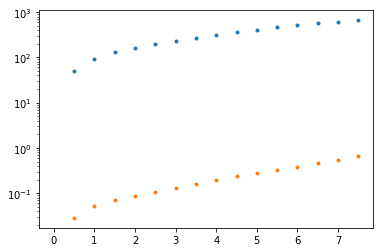

In [7]:
Vtest = np.arange(0, 8, 0.5)

plt.semilogy(Vtest, DNvsVov_40(Vtest), '.')
plt.semilogy(Vtest, DNvsVov_110(Vtest), '.');

### Data folding ###
* folded Giacomo's DN vs. V data into DN vs. T
* below plotted for 4.5V

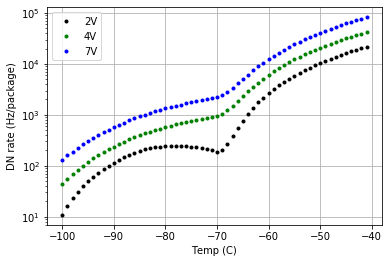

In [10]:
Ttest = np.arange(-100, -40, 1)
plt.semilogy(Ttest, DNvsT_dict.get(2)(Ttest)*4*36, 'k.', label = "2V")
plt.semilogy(Ttest, DNvsT_dict.get(4)(Ttest)*4*36, 'g.', label = "4V")
plt.semilogy(Ttest, DNvsT_dict.get(7)(Ttest)*4*36, 'b.', label = "7V")

plt.legend()
plt.xlabel("Temp (C)")
plt.ylabel("DN rate (Hz/package)");
plt.grid()

In [7]:
#returns the DN rate (Hz) for a given V, temp, and number of packages
def getRSiPM(temp: float, Vover: float, Npackages: float):
    #temp in celsius
    #Vover overvoltage for source and target SiPMs
    #Npackages: how many SiPM packages are used. 1 --> 4 quadrants or 1 package
    
    Afull = 5.85*5.95 * 4
    #Aquad = Afull/4
    
    DNrate = DNvsT_dict.get(Vover)(temp)
    rate = Afull*DNrate*Npackages
    
    return rate #in Hz

def getNSource(dataTime: float, temp: float, VSover: float, Npackages: float):
    #dataTime in hrs, must convert to seconds bc DN values in Hz
    time = dataTime*60*60
    return time*getRSiPM(temp = temp, Vover = VSover, Npackages = Npackages)

def P_rcoin(tcoin: float, temp:float, VTover:float, Npackages:float): #probability one or more event is in timewindow Tcoin
    #tcoin is acceptable coincidence window (ns)
    
    rate = getRSiPM(temp, VTover, Npackages)
    tcoin = tcoin * 1e-9
    
    return 1 - np.exp(-rate*tcoin)

def Ntarget_RC(Nsource, tcoin: float, temp:float, VTover:float, Npackages:float):
    prob = P_rcoin(tcoin, temp, VTover, Npackages)
    return Nsource*prob
    
def Ntarget_XT(Nsource, Pst):
    return Nsource*Pst

P_rcoin(tcoin = 32, temp = -95, VTover = 7.5, Npackages=4)

4.310462840917406e-05

In [8]:
## data for rate plotting ##

temps = np.array([-40, -60, -80, -95, -110])
Ntarget = 1
Nsource = 1
Vt = 7
Vs = 7
deltat = 16
p3 = 10**-3
p4 = 10**-4
p5 = 10**-5

In [30]:
# rates #
rate7 = 2*getRSiPM(temps, 7, Npackages = 1)
rate4 = 2*getRSiPM(temps, 4, Npackages = 1)

tlow = -105
thigh = -90
Vover = 6

print(getRSiPM(tlow, Vover + 1, Npackages = 1))
print(getRSiPM(thigh, Vover, Npackages = 1))

#print(P_rcoin(tcoin = 2500, temp = -80, VTover = 4, Npackages = 16))

#random rates
rand_16ns_7V = P_rcoin(tcoin = deltat, temp = temps, VTover = 7, Npackages = 1)*rate7/2
rand_8ns_7V = P_rcoin(tcoin = deltat/2, temp = temps, VTover = 7, Npackages = 1)*rate7/2
rand_16ns_4V = P_rcoin(tcoin = deltat, temp = temps, VTover = 4, Npackages = 1)*rate4/2

55.985994421349154
450.69818412063904


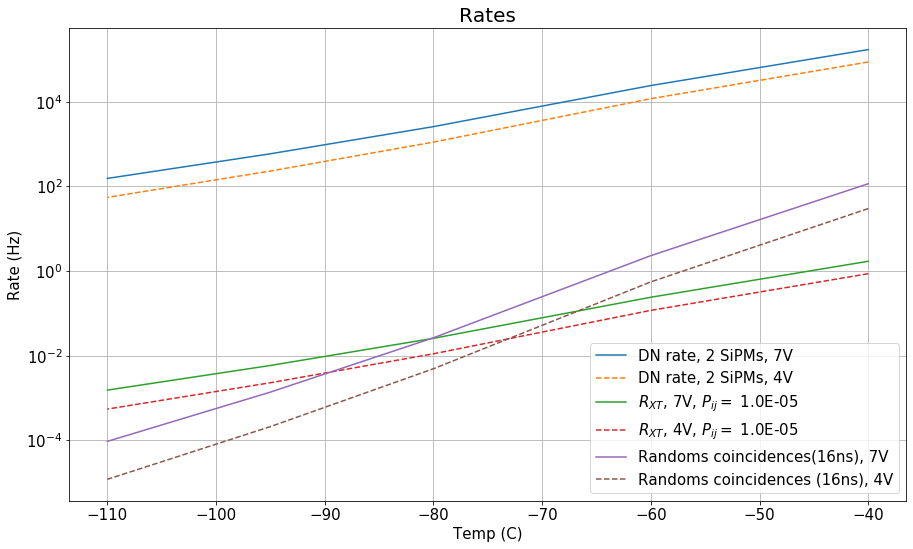

In [11]:
fig = plt.figure(figsize=(15, 15))
gs = gspec.GridSpec(2, 1, height_ratios=[2, 1])
ax1 = plt.subplot(gs[0])

#total rates
ax1.semilogy(temps, rate7, label = r'DN rate, 2 SiPMs, 7V')
ax1.semilogy(temps, rate4, '--', label = r'DN rate, 2 SiPMs, 4V')

#true coincidences
ax1.semilogy(temps, p5*rate7, '-', label = r'$R_{XT}$, 7V, $P_{ij} =$ %.1E' % p5)
#ax1.semilogy(temps, p4*rate4, '-.', label = r'4V, $P_{ij} =$ %.1E' % p4)
ax1.semilogy(temps, p5*rate4, '--', label = r'$R_{XT}$, 4V, $P_{ij} =$ %.1E' % p5)

#random rates
ax1.semilogy(temps, rand_16ns_7V, label = 'Randoms coincidences(16ns), 7V')
ax1.semilogy(temps, rand_16ns_4V, '--', label = 'Randoms coincidences (16ns), 4V')
#ax1.semilogy(temps, rand_8ns_7V, '-*', label = 'Randoms coincidences(16ns), 7V')

ax1.grid()
ax1.legend(prop={'size': 15}, loc = 'lower right')
ax1.tick_params(axis='both', which='major', labelsize=15)

ax1.set_title("Rates", fontsize = 20)
ax1.set_ylabel("Rate (Hz)", fontsize = 15)
ax1.set_xlabel("Temp (C)", fontsize = 15)

plt.subplots_adjust(hspace = 0.3)
plt.savefig("bigplot.png")
plt.show()

In [12]:
## data for resolution plotting ##
times = np.arange(1*60*60, 12*60*60, 60*60)

getRate_XT_p5_4V = interp1d(temps, p5*rate4, 'quadratic')
getRate_R_4V = interp1d(temps, rand_16ns_4V, 'quadratic')

getRate_XT_p5_7V = interp1d(temps, p5*rate7, 'quadratic')
getRate_R_7V = interp1d(temps, rand_16ns_7V, 'quadratic')

res_p5_4V_95 = (times*getRate_XT_p5_4V(-40))/np.sqrt(times*getRate_R_4V(-40))
res_p5_4V_110 = times*(getRate_XT_p5_4V(-110))/np.sqrt(times*getRate_R_4V(-110))

p5*rate4[4]*4*60*60

7.895592879093522

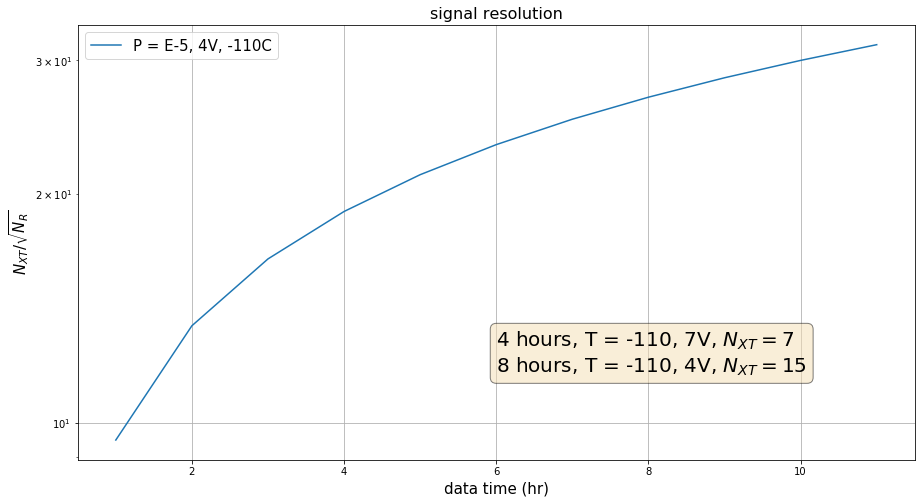

In [13]:
fig, ax2 = plt.subplots(1,1, figsize=(15, 8))

#ax2.semilogy(times/60/60, res_p5_4V_95, '-', label = "P = E-5, 4V, -90C")
ax2.semilogy(times/60/60, res_p5_4V_110, '-', label = "P = E-5, 4V, -110C")

ax2.set_ylabel(r'$N_{XT}/\sqrt{N_R}$', fontsize = 15)
ax2.set_xlabel("data time (hr)", fontsize = 15)
ax2.set_title('signal resolution', fontsize = 16)
ax2.grid()
ax2.legend(prop = {'size': 15})

getNX_4V_110 = interp1d(times, times*(getRate_XT_p5_4V(-110)))

props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
textN = '\n'.join((
    r'4 hours, T = -110, 7V, $N_{XT}=$%i' % (getNX_4V_110(4*60*60), ),
    r'8 hours, T = -110, 4V, $N_{XT}=$%i' % (getNX_4V_110(8*60*60), ),
))

ax2.text(0.5, 0.3, textN, transform=ax2.transAxes, fontsize=14, size = 20, verticalalignment='top', bbox=props)

plt.subplots_adjust(hspace = 0.3)
plt.savefig("bigplot.png")
plt.show()